In [20]:
import numpy as np
import pandas as pd

# For reproducible results
np.random.seed(42)

In [21]:
n_samples = 2000

data = {
    "Sleep_Hours": np.random.uniform(3, 10, n_samples),

    "Previous_Screen_Time": np.random.uniform(0, 12, n_samples),

    "Stress_Level": np.random.randint(1, 11, n_samples),

    "Caffeine_Intake": np.random.randint(0, 6, n_samples),

    "Study_Time": np.random.choice(
        ["Morning", "Afternoon", "Evening", "Night"],
        n_samples
    ),

    "Breaks_Taken": np.random.randint(0, 7, n_samples),

    "Task_Difficulty": np.random.randint(1, 11, n_samples),

    "Previous_Session_Score": np.random.uniform(0, 100, n_samples),

    "Phone_Notifications": np.random.randint(0, 21, n_samples),

    "Environment_Noise": np.random.randint(0, 11, n_samples),

    "Physical_Activity": np.random.randint(0, 121, n_samples),

    "Hydration_Level": np.random.randint(1, 11, n_samples),

    "Study_Environment": np.random.choice(
        ["Home", "Library", "Cafe"],
        n_samples
    )
}

df = pd.DataFrame(data)

df.head(10)

,Sleep_Hours,Previous_Screen_Time,Stress_Level,Caffeine_Intake,Study_Time,Breaks_Taken,Task_Difficulty,Previous_Session_Score,Phone_Notifications,Environment_Noise,Physical_Activity,Hydration_Level,Study_Environment
0,5.621781,3.140468,10,1,Morning,0,2,47.028848,17,10,40,2,Home
1,9.655000,2.963746,5,1,Afternoon,6,6,45.880695,17,4,92,2,Library
2,8.123958,10.875055,5,5,Evening,6,8,98.364253,12,9,69,2,Library
3,7.190609,2.994554,7,3,Morning,3,7,39.244485,7,7,81,10,Cafe
4,4.092130,3.263397,4,4,Afternoon,6,1,36.229543,11,8,48,7,Cafe
5,4.091962,9.112779,4,1,Afternoon,2,5,31.860437,20,7,43,6,Cafe
6,3.406585,5.396878,9,4,Morning,5,2,89.474922,0,2,34,1,Cafe
7,9.063233,9.320527,6,0,Night,2,6,49.672383,19,8,90,2,Home
8,7.207805,0.784394,4,1,Morning,2,7,60.001448,17,2,4,1,Cafe
9,7.956508,5.850854,2,1,Night,6,7,18.081848,2,7,70,7,Cafe


In [22]:
# Generate Focus Score
focus_score = (
    30
    + df["Sleep_Hours"] * 4
    + df["Previous_Session_Score"] * 0.15
    + df["Hydration_Level"] * 1.2
    + df["Physical_Activity"] * 0.05
    + df["Breaks_Taken"] * 1.5
    - df["Previous_Screen_Time"] * 1.2
    - df["Stress_Level"] * 1.8
    - df["Phone_Notifications"] * 0.7
    - df["Environment_Noise"] * 0.8
    - df["Task_Difficulty"] * 0.8
    + np.random.normal(0, 5, n_samples)
)

# Add time and environment effects
focus_score += df["Study_Time"].map({
    "Morning": 5,
    "Afternoon": 0,
    "Evening": 2,
    "Night": -3
})

focus_score += df["Study_Environment"].map({
    "Home": 0,
    "Library": 4,
    "Cafe": -2
})

df["Focus_Score"] = focus_score.clip(0, 100).round(2)

# Generate Classification Target
success_probability = 1 / (
    1 + np.exp(-(df["Focus_Score"] - 60) / 8)
)

df["Session_Success"] = np.random.binomial(
    1, success_probability
)

# Save dataset
from pathlib import Path

Path("../data").mkdir(parents=True, exist_ok=True)
df.to_csv("../data/focusdna_dataset.csv", index=False)

df.head(20)

,Sleep_Hours,Previous_Screen_Time,Stress_Level,Caffeine_Intake,Study_Time,Breaks_Taken,Task_Difficulty,Previous_Session_Score,Phone_Notifications,Environment_Noise,Physical_Activity,Hydration_Level,Study_Environment,Focus_Score,Session_Success
0,5.621781,3.140468,10,1,Morning,0,2,47.028848,17,10,40,2,Home,33.29,0
1,9.655000,2.963746,5,1,Afternoon,6,6,45.880695,17,4,92,2,Library,58.29,1
2,8.123958,10.875055,5,5,Evening,6,8,98.364253,12,9,69,2,Library,51.15,0
3,7.190609,2.994554,7,3,Morning,3,7,39.244485,7,7,81,10,Cafe,56.54,0
4,4.092130,3.263397,4,4,Afternoon,6,1,36.229543,11,8,48,7,Cafe,50.38,0
5,4.091962,9.112779,4,1,Afternoon,2,5,31.860437,20,7,43,6,Cafe,16.19,0
6,3.406585,5.396878,9,4,Morning,5,2,89.474922,0,2,34,1,Cafe,46.45,0
7,9.063233,9.320527,6,0,Night,2,6,49.672383,19,8,90,2,Home,28.30,0
8,7.207805,0.784394,4,1,Morning,2,7,60.001448,17,2,4,1,Cafe,52.57,0
9,7.956508,5.850854,2,1,Night,6,7,18.081848,2,7,70,7,Cafe,53.96,0


In [23]:
print("Dataset Shape:", df.shape)
print("\nMissing Values:\n", df.isnull().sum())
print("\nTarget Distribution:\n", df["Session_Success"].value_counts())
print("\nFocus Score Statistics:\n", df["Focus_Score"].describe())

Dataset Shape: (2000, 15)

Missing Values:
 Sleep_Hours               0
Previous_Screen_Time      0
Stress_Level              0
Caffeine_Intake           0
Study_Time                0
Breaks_Taken              0
Task_Difficulty           0
Previous_Session_Score    0
Phone_Notifications       0
Environment_Noise         0
Physical_Activity         0
Hydration_Level           0
Study_Environment         0
Focus_Score               0
Session_Success           0
dtype: int64

Target Distribution:
 Session_Success
0    1481
1     519
Name: count, dtype: int64

Focus Score Statistics:
 count    2000.000000
mean       46.691365
std        15.063254
min         0.000000
25%        36.500000
50%        46.685000
75%        57.447500
max        90.300000
Name: Focus_Score, dtype: float64


In [24]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Sleep_Hours             2000 non-null   float64
 1   Previous_Screen_Time    2000 non-null   float64
 2   Stress_Level            2000 non-null   int32  
 3   Caffeine_Intake         2000 non-null   int32  
 4   Study_Time              2000 non-null   str    
 5   Breaks_Taken            2000 non-null   int32  
 6   Task_Difficulty         2000 non-null   int32  
 7   Previous_Session_Score  2000 non-null   float64
 8   Phone_Notifications     2000 non-null   int32  
 9   Environment_Noise       2000 non-null   int32  
 10  Physical_Activity       2000 non-null   int32  
 11  Hydration_Level         2000 non-null   int32  
 12  Study_Environment       2000 non-null   str    
 13  Focus_Score             2000 non-null   float64
 14  Session_Success         2000 non-null   int32  
dty

In [25]:
df.describe()

,Sleep_Hours,Previous_Screen_Time,Stress_Level,Caffeine_Intake,Breaks_Taken,Task_Difficulty,Previous_Session_Score,Phone_Notifications,Environment_Noise,Physical_Activity,Hydration_Level,Focus_Score,Session_Success
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.00000,2000.00000,2000.000000,2000.00000
mean,6.490459,5.956685,5.527000,2.429000,3.046500,5.523000,49.947175,10.172000,4.967000,59.91750,5.39700,46.691365,0.25950
std,2.045476,3.462959,2.863629,1.717392,1.977952,2.835929,28.865668,6.051093,3.133021,34.74306,2.88176,15.063254,0.43847
min,3.022528,0.000140,1.000000,0.000000,0.000000,1.000000,0.108702,0.000000,0.000000,0.00000,1.00000,0.000000,0.00000
25%,4.666325,3.009441,3.000000,1.000000,1.000000,3.000000,25.556450,5.000000,2.000000,30.00000,3.00000,36.500000,0.00000
50%,6.551459,5.912332,6.000000,2.000000,3.000000,6.000000,49.978610,10.000000,5.000000,59.00000,5.00000,46.685000,0.00000
75%,8.254752,8.984286,8.000000,4.000000,5.000000,8.000000,74.478075,15.000000,8.000000,90.00000,8.00000,57.447500,1.00000
max,9.998024,11.994692,10.000000,5.000000,6.000000,10.000000,99.963563,20.000000,10.000000,120.00000,10.00000,90.300000,1.00000


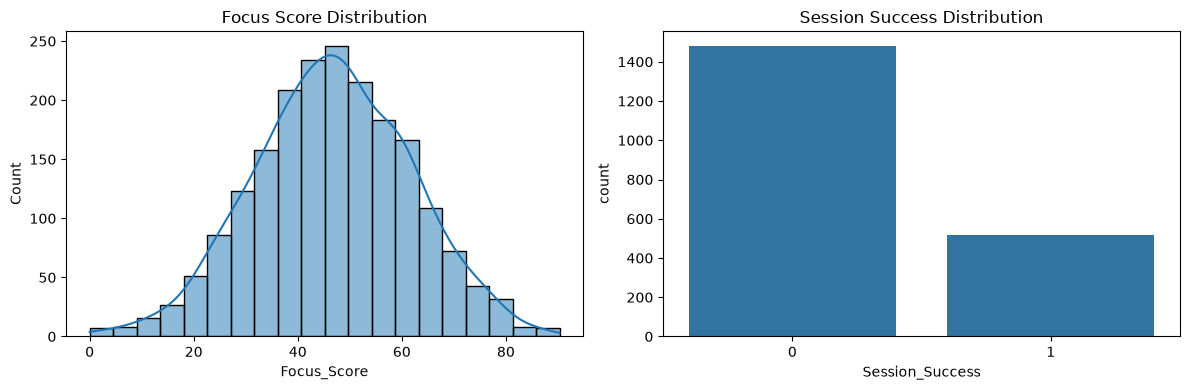

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=df, x="Focus_Score", bins=20, kde=True, ax=axes[0])
axes[0].set_title("Focus Score Distribution")

sns.countplot(data=df, x="Session_Success", ax=axes[1])
axes[1].set_title("Session Success Distribution")

plt.tight_layout()
plt.show()

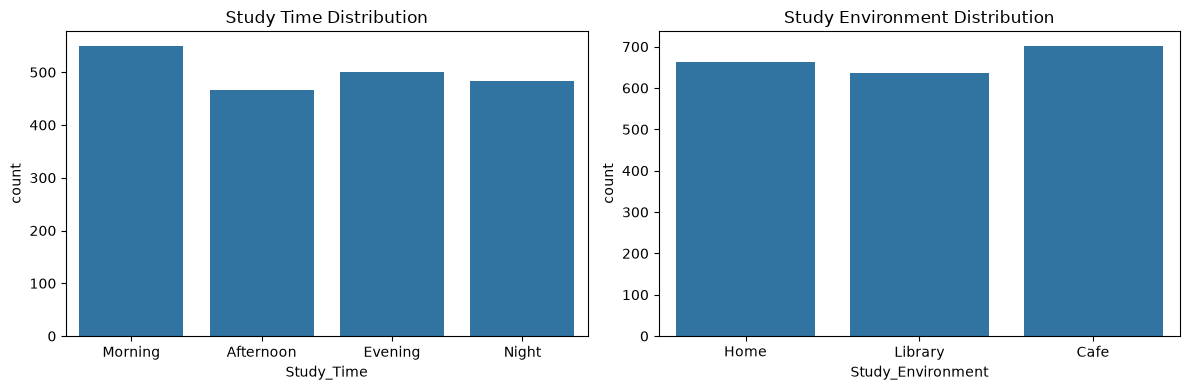

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=df, x="Study_Time", ax=axes[0])
axes[0].set_title("Study Time Distribution")

sns.countplot(data=df, x="Study_Environment", ax=axes[1])
axes[1].set_title("Study Environment Distribution")

plt.tight_layout()
plt.show()

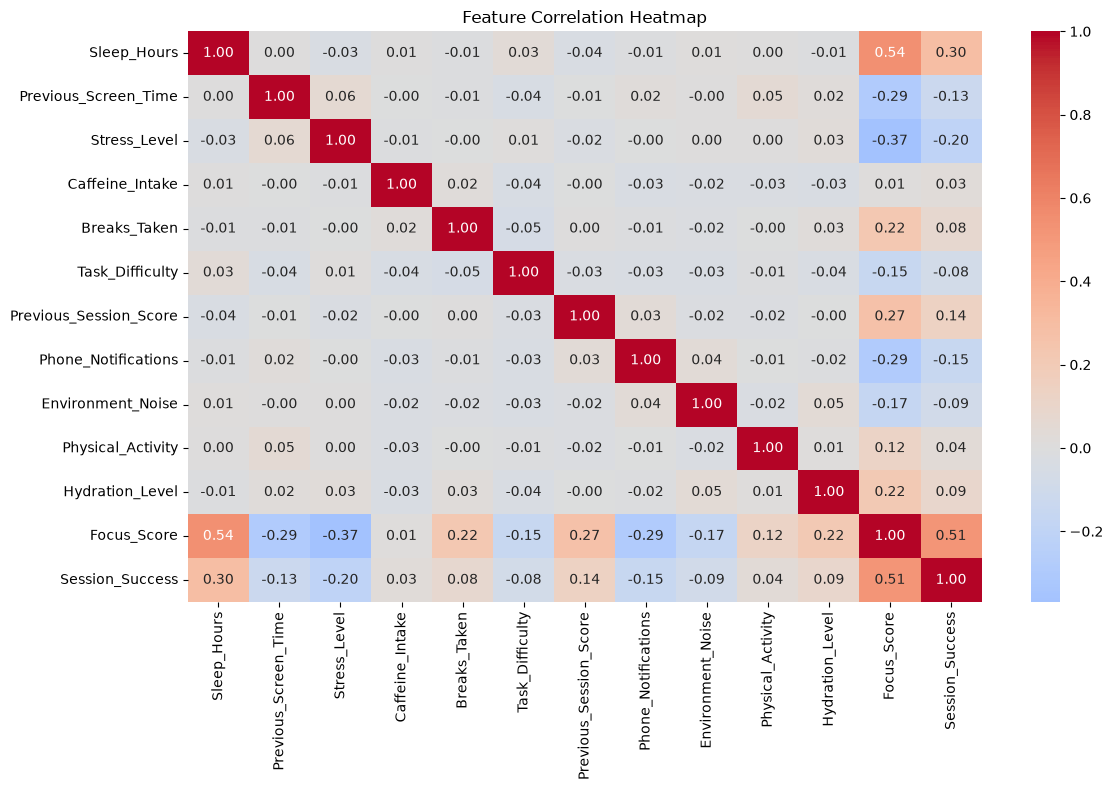

In [28]:
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

In [29]:
df.drop(
    columns=["Caffeine_Intake", "Physical_Activity"],
    inplace=True
)

df.to_csv("../data/focusdna_dataset.csv", index=False)

print("Dataset Shape:", df.shape)

Dataset Shape: (2000, 13)


In [30]:
X = df.drop(columns=["Focus_Score", "Session_Success"])

y_class = df["Session_Success"]
y_reg = df["Focus_Score"]

print("Features:", X.shape)
print("Classification Target:", y_class.shape)
print("Regression Target:", y_reg.shape)

Features: (2000, 11)
Classification Target: (2000,)
Regression Target: (2000,)


In [31]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder


categorical_features = X.select_dtypes(include=["object", "str"]).columns.tolist()
numerical_features = X.select_dtypes(exclude=["object", "str"]).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("num", "passthrough", numerical_features)
    ]
)

X_train, X_test, y_class_train, y_class_test, y_reg_train, y_reg_test = (
    train_test_split(
        X,
        y_class,
        y_reg,
        test_size=0.2,
        random_state=42,
        stratify=y_class
    )
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training set:", X_train_processed.shape)
print("Testing set:", X_test_processed.shape)


Training set: (1600, 16)
Testing set: (400, 16)


In [32]:
feature_names = preprocessor.get_feature_names_out()

print("Processed Features:")
print(feature_names)

Processed Features:
['cat__Study_Time_Afternoon' 'cat__Study_Time_Evening'
 'cat__Study_Time_Morning' 'cat__Study_Time_Night'
 'cat__Study_Environment_Cafe' 'cat__Study_Environment_Home'
 'cat__Study_Environment_Library' 'num__Sleep_Hours'
 'num__Previous_Screen_Time' 'num__Stress_Level' 'num__Breaks_Taken'
 'num__Task_Difficulty' 'num__Previous_Session_Score'
 'num__Phone_Notifications' 'num__Environment_Noise'
 'num__Hydration_Level']


In [33]:
from sklearn.feature_selection import SelectKBest, f_classif

selector_class = SelectKBest(score_func=f_classif, k=8)

X_train_class_selected = selector_class.fit_transform(
    X_train_processed, y_class_train
)

X_test_class_selected = selector_class.transform(X_test_processed)

selected_class_features = feature_names[selector_class.get_support()]

print("Selected Classification Features:")
print(selected_class_features)

Selected Classification Features:
['cat__Study_Time_Morning' 'cat__Study_Environment_Library'
 'num__Sleep_Hours' 'num__Previous_Screen_Time' 'num__Stress_Level'
 'num__Previous_Session_Score' 'num__Phone_Notifications'
 'num__Hydration_Level']


In [34]:
from sklearn.feature_selection import SelectKBest, f_regression

selector_reg = SelectKBest(score_func=f_regression, k=8)

X_train_reg_selected = selector_reg.fit_transform(
    X_train_processed, y_reg_train
)

X_test_reg_selected = selector_reg.transform(X_test_processed)

selected_reg_features = feature_names[selector_reg.get_support()]

print("Selected Regression Features:")
print(selected_reg_features)

Selected Regression Features:
['cat__Study_Time_Morning' 'num__Sleep_Hours' 'num__Previous_Screen_Time'
 'num__Stress_Level' 'num__Breaks_Taken' 'num__Previous_Session_Score'
 'num__Phone_Notifications' 'num__Hydration_Level']


In [35]:
print("Classification:", len(selected_class_features), "features")
print("Regression:", len(selected_reg_features), "features")

Classification: 8 features
Regression: 8 features


In [36]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42)
}

In [39]:
classification_results = []

for name, model in classifiers.items():

    # All features
    model.fit(X_train_processed, y_class_train)
    predictions = model.predict(X_test_processed)

    classification_results.append({
        "Model": name,
        "Features": "All",
        "Accuracy": accuracy_score(y_class_test, predictions),
        "Precision": precision_score(y_class_test, predictions, zero_division=0),
        "Recall": recall_score(y_class_test, predictions, zero_division=0),
        "F1-Score": f1_score(y_class_test, predictions, zero_division=0)
    })

    # Selected features
    model_selected = type(model)(**model.get_params())
    model_selected.fit(X_train_class_selected, y_class_train)
    predictions_selected = model_selected.predict(X_test_class_selected)

    classification_results.append({
        "Model": name,
        "Features": "Selected",
        "Accuracy": accuracy_score(y_class_test, predictions_selected),
        "Precision": precision_score(y_class_test, predictions_selected, zero_division=0),
        "Recall": recall_score(y_class_test, predictions_selected, zero_division=0),
        "F1-Score": f1_score(y_class_test, predictions_selected, zero_division=0)
    })

classification_df = pd.DataFrame(classification_results)

classification_df.sort_values(
    by="F1-Score", ascending=False
).round(3)

,Model,Features,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,All,0.785,0.622,0.442,0.517
1,Logistic Regression,Selected,0.788,0.656,0.385,0.485
7,Random Forest,Selected,0.760,0.577,0.288,0.385
5,Decision Tree,Selected,0.685,0.390,0.375,0.382
4,Decision Tree,All,0.658,0.354,0.385,0.369
6,Random Forest,All,0.772,0.667,0.250,0.364
2,KNN,All,0.728,0.455,0.240,0.314
3,KNN,Selected,0.700,0.386,0.260,0.310


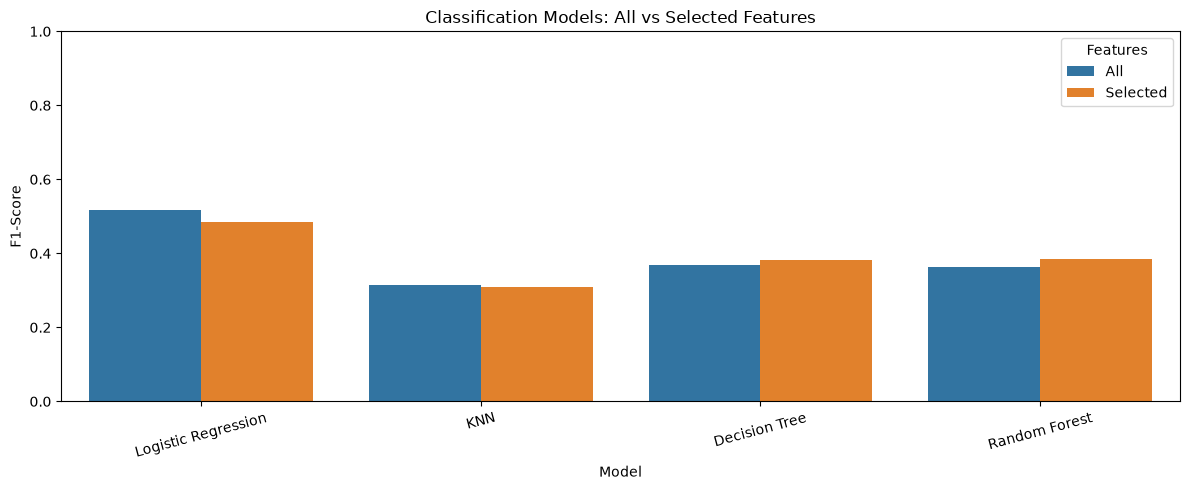

In [38]:
plt.figure(figsize=(12, 5))

sns.barplot(
    data=classification_df,
    x="Model",
    y="F1-Score",
    hue="Features"
)

plt.title("Classification Models: All vs Selected Features")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

              precision    recall  f1-score   support

           0       0.82      0.91      0.86       296
           1       0.62      0.44      0.52       104

    accuracy                           0.79       400
   macro avg       0.72      0.67      0.69       400
weighted avg       0.77      0.79      0.77       400



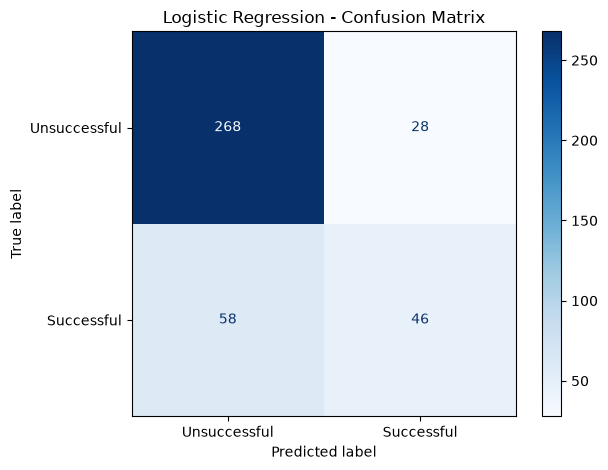

In [42]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

best_classifier = LogisticRegression(max_iter=1000)
best_classifier.fit(X_train_processed, y_class_train)

y_class_pred = best_classifier.predict(X_test_processed)

print(classification_report(y_class_test, y_class_pred))

ConfusionMatrixDisplay.from_predictions(
    y_class_test,
    y_class_pred,
    display_labels=["Unsuccessful", "Successful"],
    cmap="Blues"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

In [43]:
classification_df.to_csv(
    "../data/classification_results.csv",
    index=False
)

In [44]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

regressors = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42)
}

In [45]:
regression_results = []

for name, model in regressors.items():

    # All features
    model.fit(X_train_processed, y_reg_train)
    predictions = model.predict(X_test_processed)

    regression_results.append({
        "Model": name,
        "Features": "All",
        "MAE": mean_absolute_error(y_reg_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_reg_test, predictions)),
        "R2": r2_score(y_reg_test, predictions)
    })

    # Selected features
    model_selected = type(model)(**model.get_params())
    model_selected.fit(X_train_reg_selected, y_reg_train)
    predictions_selected = model_selected.predict(X_test_reg_selected)

    regression_results.append({
        "Model": name,
        "Features": "Selected",
        "MAE": mean_absolute_error(y_reg_test, predictions_selected),
        "RMSE": np.sqrt(mean_squared_error(y_reg_test, predictions_selected)),
        "R2": r2_score(y_reg_test, predictions_selected)
    })

regression_df = pd.DataFrame(regression_results)

regression_df.sort_values(
    by="R2", ascending=False
).round(3)

,Model,Features,MAE,RMSE,R2
0,Linear Regression,All,4.314,5.377,0.873
1,Linear Regression,Selected,5.454,6.844,0.794
4,Random Forest,All,5.973,7.584,0.747
5,Random Forest,Selected,6.235,7.861,0.728
2,Decision Tree,All,9.311,11.696,0.397
3,Decision Tree,Selected,9.766,12.259,0.338


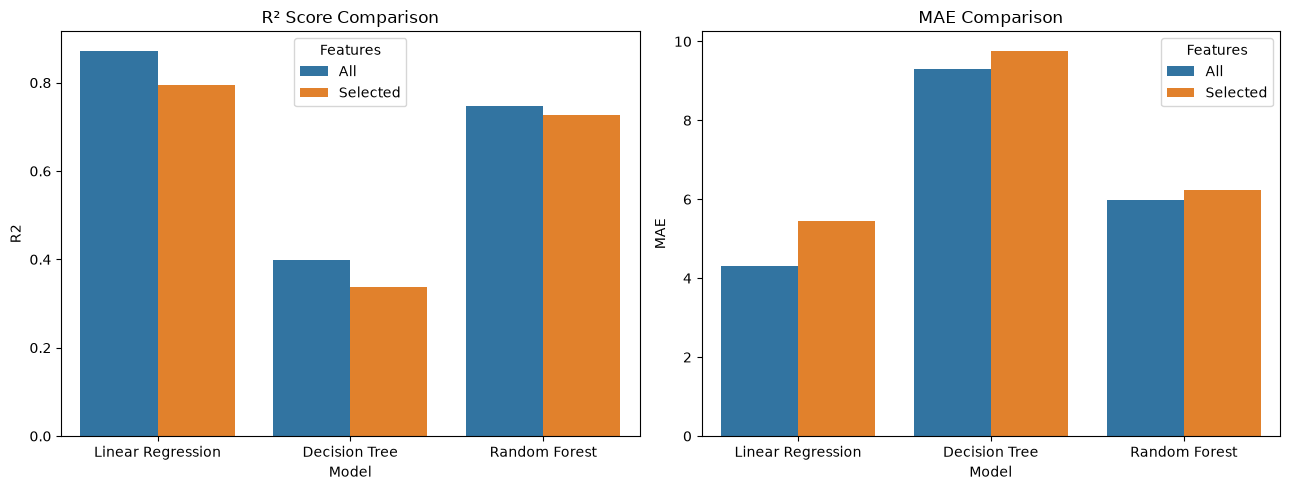

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(
    data=regression_df,
    x="Model",
    y="R2",
    hue="Features",
    ax=axes[0]
)
axes[0].set_title("R² Score Comparison")

sns.barplot(
    data=regression_df,
    x="Model",
    y="MAE",
    hue="Features",
    ax=axes[1]
)
axes[1].set_title("MAE Comparison")

plt.tight_layout()
plt.show()

In [47]:
regression_df.to_csv(
    "../data/regression_results.csv",
    index=False
)

In [48]:
best_regressor = LinearRegression()

best_regressor.fit(X_train_processed, y_reg_train)

y_reg_pred = best_regressor.predict(X_test_processed)

print("MAE:", round(mean_absolute_error(y_reg_test, y_reg_pred), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_reg_test, y_reg_pred)), 3))
print("R2:", round(r2_score(y_reg_test, y_reg_pred), 3))

MAE: 4.314
RMSE: 5.377
R2: 0.873


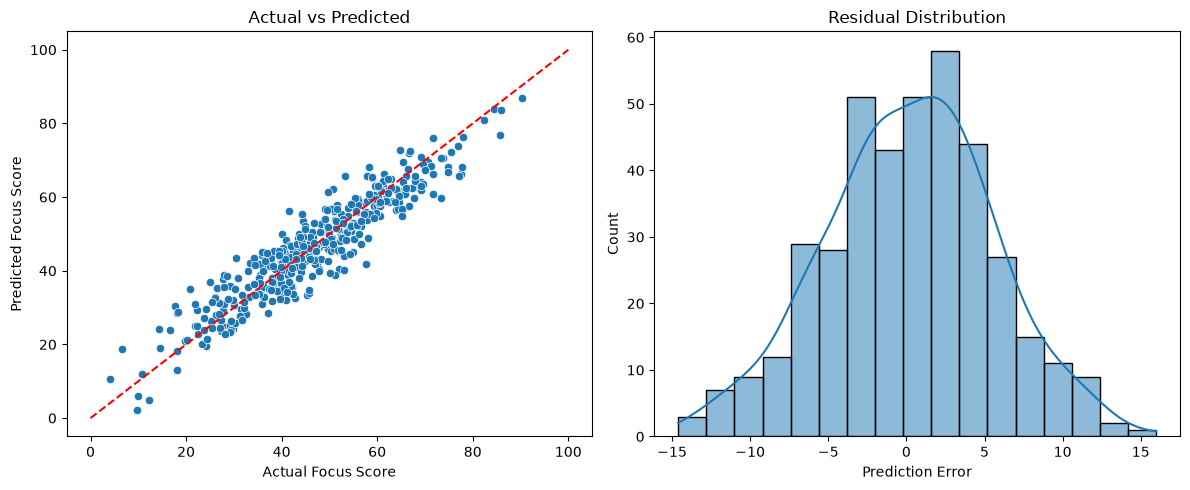

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.scatterplot(x=y_reg_test, y=y_reg_pred, ax=axes[0])

axes[0].plot([0, 100], [0, 100], "r--")
axes[0].set_xlabel("Actual Focus Score")
axes[0].set_ylabel("Predicted Focus Score")
axes[0].set_title("Actual vs Predicted")

residuals = y_reg_test - y_reg_pred

sns.histplot(residuals, kde=True, ax=axes[1])
axes[1].set_title("Residual Distribution")
axes[1].set_xlabel("Prediction Error")

plt.tight_layout()
plt.show()

In [51]:
regression_df.to_csv(
    "../data/regression_results.csv",
    index=False
)

,Feature,Coefficient,Absolute_Importance
2,cat__Study_Time_Morning,4.192,4.192
7,num__Sleep_Hours,3.983,3.983
3,cat__Study_Time_Night,-3.845,3.845
6,cat__Study_Environment_Library,3.602,3.602
4,cat__Study_Environment_Cafe,-2.644,2.644
9,num__Stress_Level,-1.813,1.813
10,num__Breaks_Taken,1.449,1.449
15,num__Hydration_Level,1.240,1.240
0,cat__Study_Time_Afternoon,-1.223,1.223
8,num__Previous_Screen_Time,-1.218,1.218


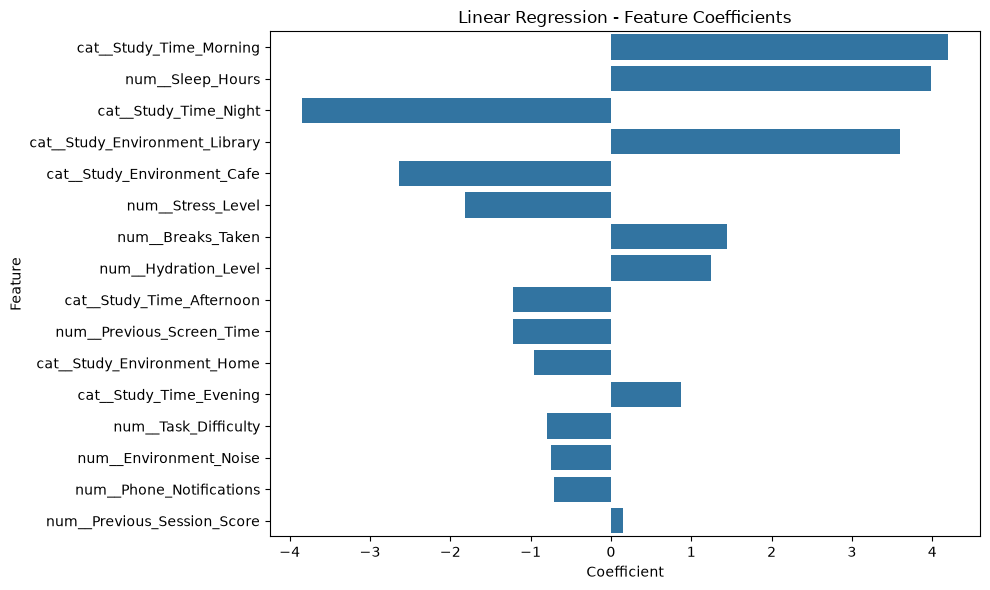

In [52]:
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": best_regressor.coef_
})

importance_df["Absolute_Importance"] = (
    importance_df["Coefficient"].abs()
)

importance_df = importance_df.sort_values(
    "Absolute_Importance", ascending=False
)

display(importance_df.round(3))

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x="Coefficient",
    y="Feature"
)

plt.title("Linear Regression - Feature Coefficients")
plt.tight_layout()
plt.show()

In [53]:
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import joblib
from pathlib import Path

models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

# Classification model
final_classifier = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000, random_state=42))
])

final_classifier.fit(X_train_processed, y_class_train)

# Regression model
final_regressor = LinearRegression()
final_regressor.fit(X_train_processed, y_reg_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [54]:
joblib.dump(preprocessor, models_dir / "preprocessor.pkl")
joblib.dump(final_classifier, models_dir / "classifier.pkl")
joblib.dump(final_regressor, models_dir / "regressor.pkl")

joblib.dump(
    list(X.columns),
    models_dir / "input_features.pkl"
)

joblib.dump(
    list(feature_names),
    models_dir / "processed_features.pkl"
)

print("Models and preprocessing saved successfully!")

Models and preprocessing saved successfully!


In [55]:
for file in models_dir.iterdir():
    print(file.name)

classifier.pkl
input_features.pkl
preprocessor.pkl
processed_features.pkl
regressor.pkl


In [56]:
from pathlib import Path

data_dir = Path("../data")
data_dir.mkdir(parents=True, exist_ok=True)

classification_df.to_csv(
    data_dir / "classification_results.csv",
    index=False
)

regression_df.to_csv(
    data_dir / "regression_results.csv",
    index=False
)

print("Results saved successfully!")

Results saved successfully!
